# Automobile Sales During Recessions

Visual analysis of historical automobile sales (1980-2023) to explain how recessions affect sales by vehicle type, advertising, GDP, seasonality and unemployment, plus a Dash dashboard.


In [31]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import folium

In [32]:
import requests
import io
import pandas as pd

# URL of the CSV file
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"

# Fetch the data from the URL
response = requests.get(URL)

# Raise an error if the request failed
response.raise_for_status()

# Convert the response content into a readable format for pandas
csv_content = io.StringIO(response.text)

# Read the CSV data into a pandas dataframe
df = pd.read_csv(csv_content)

# Print confirmation
print('Data downloaded and read into a dataframe!')

# Optional: Show the first few rows of the dataframe
print(df.head())

Data downloaded and read into a dataframe!
         Date  Year Month  Recession  Consumer_Confidence  Seasonality_Weight  \
0  1980-01-31  1980   Jan          1               108.24                0.45   
1  1980-01-31  1980   Jan          1               108.24                0.45   
2  1980-01-31  1980   Jan          1               108.24                0.36   
3  1980-01-31  1980   Jan          1               108.24                0.38   
4  1980-02-29  1980   Feb          1                98.75                0.46   

   Price  Advertising_Expenditure  Competition    GDP  Growth_Rate  \
0  27704                   1417.5            7  60.22         0.01   
1  77270                    763.7            7  60.22         0.01   
2  19665                   1417.5            7  60.22         0.01   
3  36986                   1417.5            7  60.22         0.01   
4  26609                   2773.4            4  45.99        -0.31   

   unemployment_rate  Automobile_Sales     Vehicl

In [33]:
df.describe()

,Year,Recession,Consumer_Confidence,Seasonality_Weight,Price,Advertising_Expenditure,Competition,GDP,Growth_Rate,unemployment_rate,Automobile_Sales
count,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000,2112.000000
mean,2001.520833,0.224432,101.210890,0.737756,41469.506155,2879.743655,6.118845,40.205748,-0.237074,2.441525,3164.160511
std,12.535031,0.417306,10.634092,0.286092,21388.409141,1175.338324,1.964292,16.291271,0.859691,1.108472,3640.137399
min,1980.000000,0.000000,73.900000,0.250000,15001.000000,494.200000,3.000000,12.510000,-4.230000,1.000000,40.000000
25%,1991.000000,0.000000,94.060000,0.500000,22039.000000,1872.000000,4.000000,27.210000,-0.570000,1.600000,923.000000
50%,2002.000000,0.000000,100.800000,0.810000,34957.500000,2883.500000,6.000000,39.420000,-0.005000,2.300000,2381.500000
75%,2012.000000,0.000000,108.320000,0.940000,57418.250000,3902.425000,8.000000,53.862500,0.392500,2.900000,4363.500000
max,2023.000000,1.000000,131.670000,1.500000,79998.000000,4983.000000,9.000000,70.370000,0.820000,6.000000,65645.000000


In [34]:
df.columns

Index(['Date', 'Year', 'Month', 'Recession', 'Consumer_Confidence',
       'Seasonality_Weight', 'Price', 'Advertising_Expenditure', 'Competition',
       'GDP', 'Growth_Rate', 'unemployment_rate', 'Automobile_Sales',
       'Vehicle_Type', 'City'],
      dtype='str')

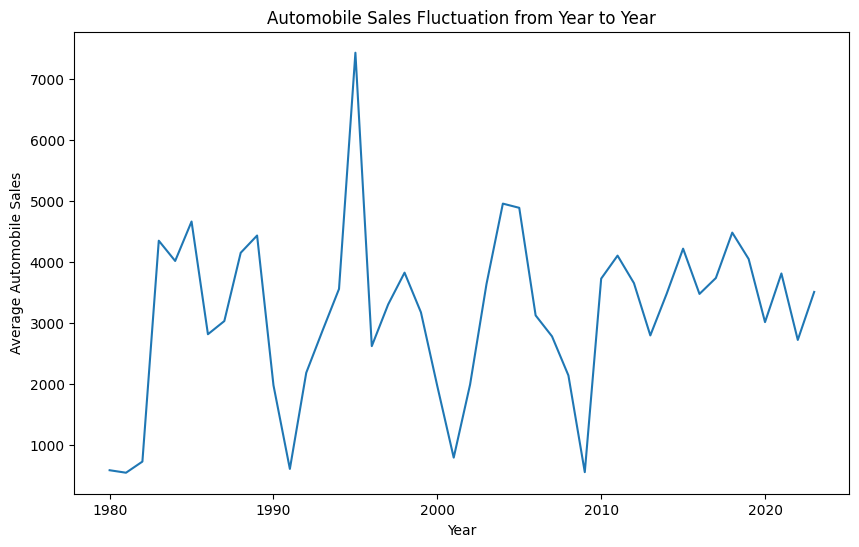

In [35]:
df_line = df.groupby(df['Year'])['Automobile_Sales'].mean()

# create figure
plt.figure(figsize=(10, 6))
df_line.plot(kind='line')
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.title('Automobile Sales Fluctuation from Year to Year')
plt.show()


Extreme Volatility and Global Maximum: The market experiences dramatic, rapid shifts, most notably highlighted by a massive spike around 1995 where average sales peaked at nearly 7,500 units before immediately collapsing.   Periodic Market Troughs: The data reveals steep, recurring drops in sales volume roughly every decade. Significant crashes occurred near 1980, 1991, 2001, and 2009, with average sales regularly plummeting below 1,000 units during these distinct downturns.   Recent Trend Compression: Following the deep trough around 2009, the magnitude of the fluctuations has dampened. Between 2010 and 2023, sales continued to cycle up and down but remained within a tighter band of approximately 2,500 to 4,500 units.   Ultimately, this historical pattern points to an industry highly sensitive to external macroeconomic cycles—the major troughs align closely with known historical recessions—meaning any predictive forecasting models must heavily weight cyclical market corrections rather than relying on simple linear progression.

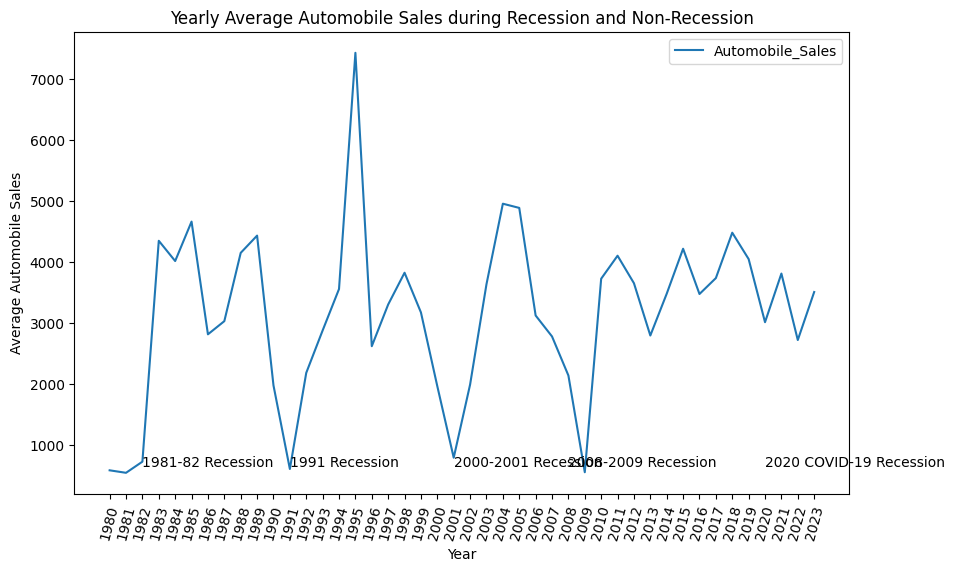

In [36]:
df_line = df.groupby(df['Year'])['Automobile_Sales'].mean()

plt.figure(figsize=(10, 6))
df_line.plot(kind='line')
plt.xticks(list(range(1980, 2024)), rotation=75)
plt.xlabel('Year')
plt.ylabel('Average Automobile Sales')
plt.title('Yearly Average Automobile Sales during Recession and Non-Recession')
plt.text(1982, 650, '1981-82 Recession')
plt.text(1991, 650, '1991 Recession')
plt.text(2001, 650, '2000-2001 Recession')
plt.text(2008, 650, '2008-2009 Recession')
plt.text(2020, 650, '2020 COVID-19 Recession')
plt.legend()
plt.show()

Direct Correlation with Economic Downturns: Every major collapse in average sales volume aligns perfectly with a labeled recessionary period: 1981-82, 1991, 2000-2001, 2008-2009, and the 2020 COVID-19 recession. This indicates that automobile purchases are highly elastic and strongly tied to overall consumer confidence and economic health.   Varying Severity of Impact: The historical recessions of 1981-82, 1991, 2001, and 2008-2009 were catastrophic for sales, causing averages to plummet well below 1,000 units. In contrast, the 2020 COVID-19 recession shows a notably softer impact on this specific metric, with sales dipping only to approximately 3,000 units.   Post-Recession Recovery Bounces: Following almost every recessionary trough, the data shows sharp, immediate recoveries (such as the spikes after 1982, 1991, and 2009), indicating rapid normalization of consumer purchasing behavior once economic stability returns.   

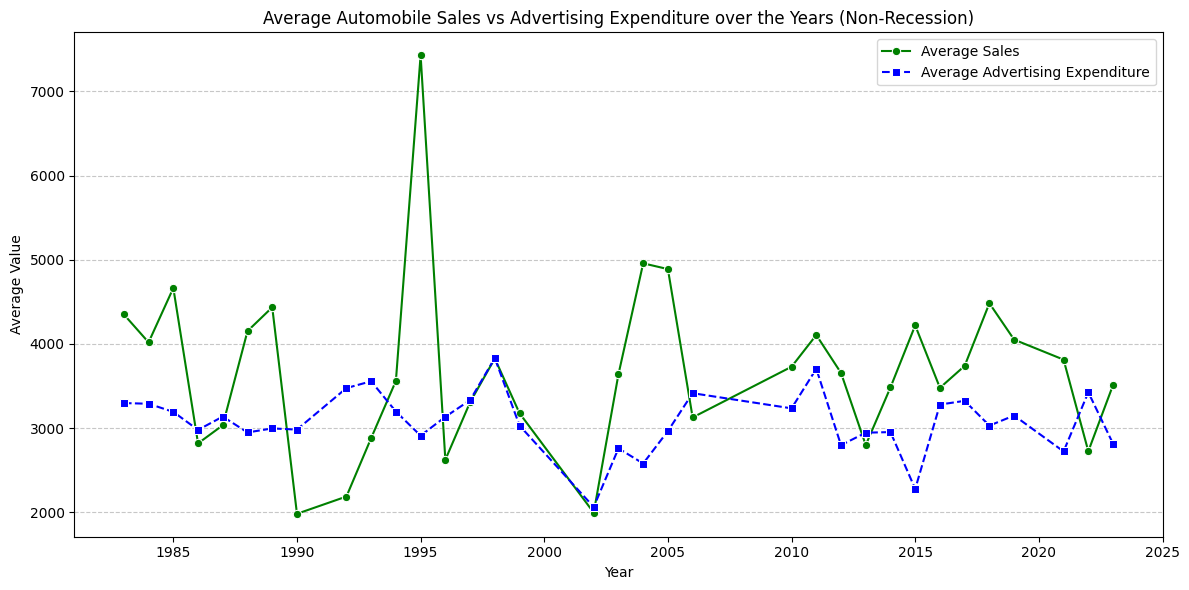

In [37]:
df_non_rec = df[df['Recession'] == 0]

# Calculate average automobile sales and average advertising expenditure by year (non-recession)
df_trends = df_non_rec.groupby('Year', as_index=False).agg(
    Avg_Sales=('Automobile_Sales', 'mean'),
    Avg_Ad_Spend=('Advertising_Expenditure', 'mean')
)

# Create line plots for average sales and advertising expenditure over the years
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_trends, x='Year', y='Avg_Sales', marker='o', linestyle='-', color='green', label='Average Sales')
sns.lineplot(data=df_trends, x='Year', y='Avg_Ad_Spend', marker='s', linestyle='--', color='blue', label='Average Advertising Expenditure')

# Add labels, legend, title, and grid
plt.xlabel('Year')
plt.ylabel('Average Value')
plt.title('Average Automobile Sales vs Advertising Expenditure over the Years (Non-Recession)')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()

Divergent Volatility Profiles: While average automobile sales exhibit massive, erratic swings (most notably the spike around 1995 exceeding 7,000 units), average advertising expenditure remains relatively stable, fluctuating within a much tighter band of 2,000 to 4,000 units.   Lack of Strong Correlation: There is no consistent visual evidence that surges in ad spend trigger proportional surges in sales. The dramatic 1995 sales peak occurred while advertising expenditure was actually trending slightly downward or remaining flat relative to surrounding years.   Advertising as a Baseline Investment: The blue dashed line indicates that the industry treats advertising more as a steady, baseline operational cost rather than a highly elastic lever. Even when sales dip significantly during these non-recession years, ad spend often remains steady or even increases slightly (as seen around 1990 and 2015).  

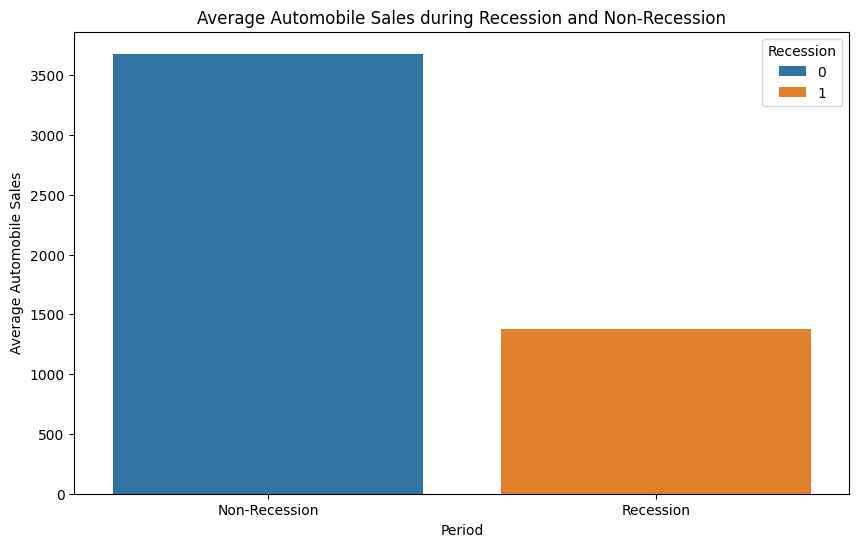

In [38]:
new_df = df.groupby('Recession')['Automobile_Sales'].mean().reset_index()

# Create the bar chart using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Recession', data=new_df)
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Average Automobile Sales during Recession and Non-Recession')
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.show()

Significant Volume Reduction: Average automobile sales drop from approximately 3,600 units during non-recessionary periods to roughly 1,300 units during recessions.   Proportional Impact: This data demonstrates a massive contraction, with average sales volumes during economic downturns falling to less than half of their typical non-recessionary levels.   Validation of Market Sensitivity: This clear aggregate view reinforces earlier time-series findings, confirming that the automotive sector is highly elastic and fundamentally tethered to broader macroeconomic health.

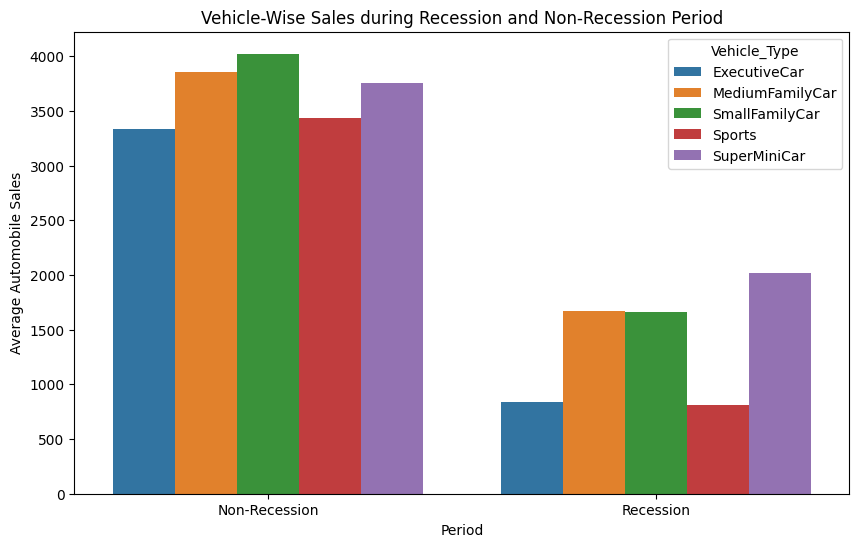

In [39]:
grouped_df = df.groupby(['Recession', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()

# Create the grouped bar chart using seaborn
plt.figure(figsize=(10, 6))
sns.barplot(x='Recession', y='Automobile_Sales', hue='Vehicle_Type', data=grouped_df)
plt.xticks(ticks=[0, 1], labels=['Non-Recession', 'Recession'])
plt.xlabel('Period')
plt.ylabel('Average Automobile Sales')
plt.title('Vehicle-Wise Sales during Recession and Non-Recession Period')

plt.show()

Universal Contraction: Average sales across all five tracked vehicle categories (Executive, Medium Family, Small Family, Sports, and SuperMini) fall significantly during recessionary periods compared to non-recessionary periods.   Severe Impact on Discretionary Segments: High-end and performance vehicles suffer the most dramatic absolute and relative collapses. Both "ExecutiveCar" and "Sports" categories plummet from roughly 3,300–3,400 average units in healthy economies to under 1,000 units during recessions.   Shift in Market Leadership: Consumer preference shifts defensively during downturns. While the "SmallFamilyCar" is the top-selling category during non-recession periods (peaking around 4,000 units), the "SuperMiniCar" overtakes all other segments to become the clear market leader during recessions.   Economy Vehicle Resilience: "SuperMiniCar" sales demonstrate the highest relative market resilience, maintaining an average of approximately 2,000 units during recessions, which is significantly higher than the next closest categories (Medium and Small Family cars).   

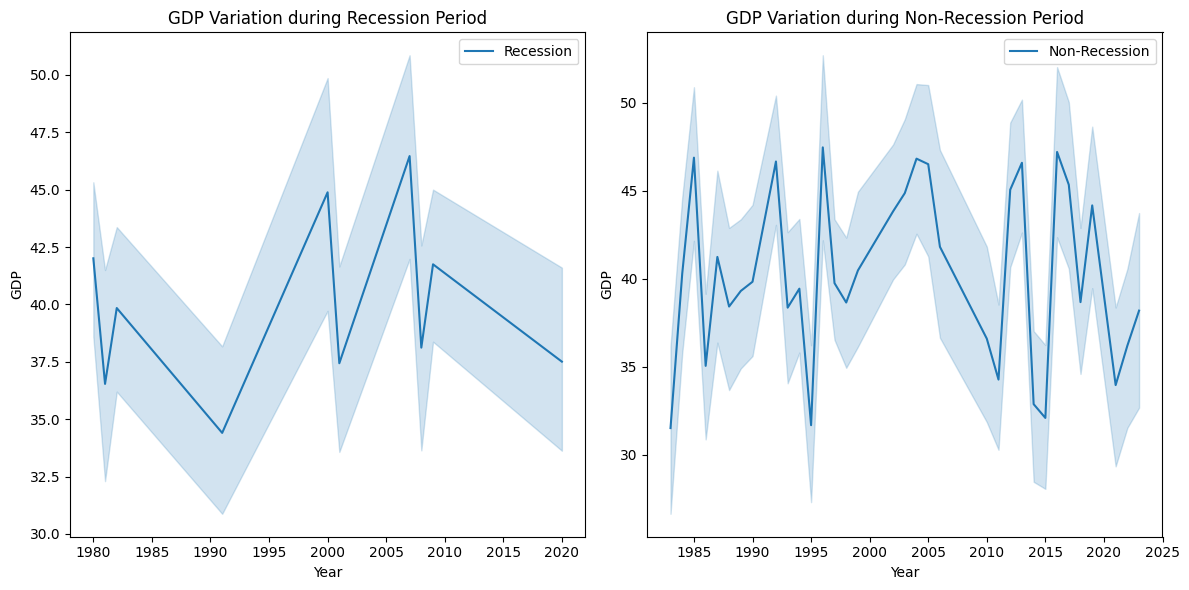

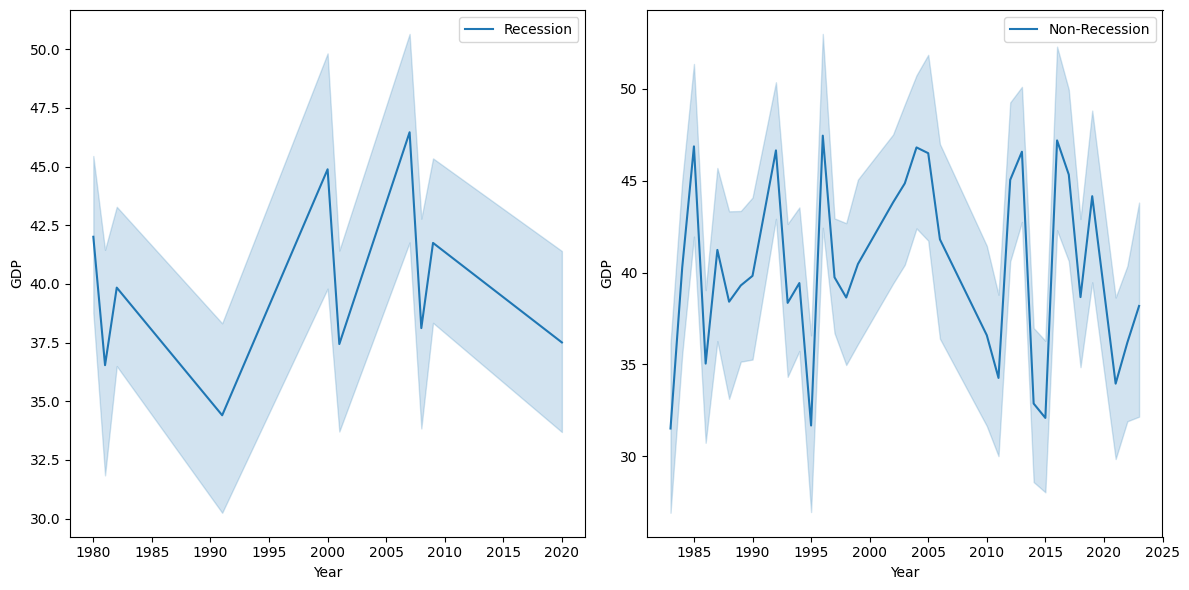

In [40]:
# Create dataframes for recession and non-recession period
rec_data = df[df['Recession'] == 1]
non_rec_data = df[df['Recession'] == 0]

# Figure
fig = plt.figure(figsize=(12, 6))

# Create different axes for subplotting
ax0 = fig.add_subplot(1, 2, 1)  # add subplot 1 (1 row, 2 columns, first plot)
ax1 = fig.add_subplot(1, 2, 2)  # add subplot 2 (1 row, 2 columns, second plot)

# plt.subplot(1, 2, 1)
sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession', ax=ax0)
ax0.set_xlabel('Year')
ax0.set_ylabel('GDP')
ax0.set_title('GDP Variation during Recession Period')

# plt.subplot(1, 2, 2)
sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession', ax=ax1)
ax1.set_xlabel('Year')
ax1.set_ylabel('GDP')
ax1.set_title('GDP Variation during Non-Recession Period')

plt.tight_layout()
plt.show()

# ------------------------------------------------Alternatively--------------
# Using subplot()
plt.figure(figsize=(12, 6))

# subplot 1
plt.subplot(1, 2, 1)
sns.lineplot(x='Year', y='GDP', data=rec_data, label='Recession')
plt.xlabel('Year')
plt.ylabel('GDP')
plt.legend()

# subplot 2
plt.subplot(1, 2, 2)
sns.lineplot(x='Year', y='GDP', data=non_rec_data, label='Non-Recession')
plt.xlabel('Year')
plt.ylabel('GDP')
plt.legend()

plt.tight_layout()
plt.show()

Direct Link to Industry Contraction: During recession periods, GDP drops to noticeable lower points—reaching severe troughs around 34–37 during the 1991, 2001, and 2008–2009 downturns. This decline in aggregate economic output directly correlates with the steep drops in vehicle purchase volumes, particularly for discretionary vehicle segments.   Heightened Economic Uncertainty: The shaded confidence bands on the recession plot widen significantly around major downturns. This indicates substantially higher volatility and economic unpredictability during recessionary years compared to normal growth cycles.   Strong Non-Recession Baselines: In non-recession years, GDP consistently recovers to higher peaks (frequently reaching between 45 and 48). This expanded purchasing power provides the necessary economic foundation to support high average sales of family and luxury vehicles. 

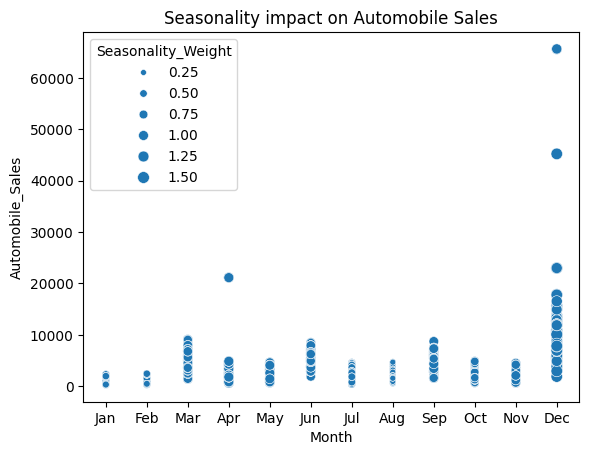

In [41]:
non_rec_data = df[df['Recession'] == 0]

size = non_rec_data['Seasonality_Weight']  # for bubble effect

sns.scatterplot(data=non_rec_data, x='Month', y='Automobile_Sales', size=size)

# you can further include hue='Seasonality_Weight', legend=False)

plt.xlabel('Month')
plt.ylabel('Automobile_Sales')
plt.title('Seasonality impact on Automobile Sales')

plt.show()

December Demand Shock: December is the clear peak for sales volume, featuring extreme positive outliers reaching well over 60,000 units. This month exclusively carries the highest seasonality weight multipliers (approaching 1.50), indicating systemic, recurring end-of-year buying surges rather than random variance.   End-of-Quarter Clustering: Beyond the massive December spike, minor but distinct volume clusters appear in March, June, and September. These regular bumps likely reflect standard dealership sales quota pushes and quarter-end financial incentives.   Low-Variance Troughs: The beginning and middle of most quarters (January, February, May, July, August, October, November) represent stagnant periods where sales tightly cluster below the 5,000-unit mark with minimal variance and low seasonality weights.   

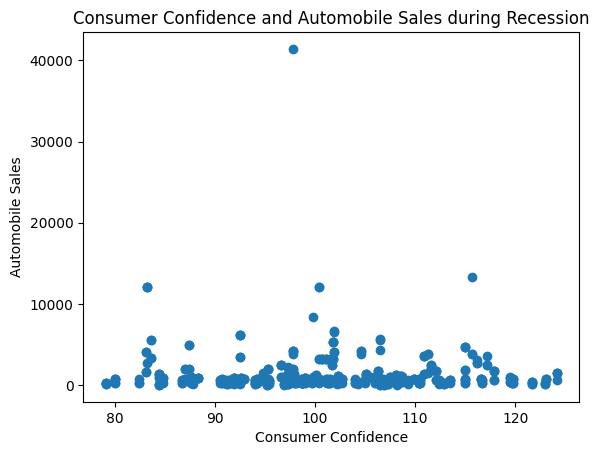

In [42]:
# Create dataframes for recession period
rec_data = df[df['Recession'] == 1]
plt.scatter(rec_data['Consumer_Confidence'], rec_data['Automobile_Sales'])

plt.xlabel('Consumer Confidence')
plt.ylabel('Automobile Sales')
plt.title('Consumer Confidence and Automobile Sales during Recession')
plt.show()

Absence of Linear Correlation: The data points are horizontally dispersed across the entire confidence spectrum (from 80 to 125) while remaining tightly clustered near the bottom of the y-axis, generally under 5,000 units. Feeding these two variables into a Scikit-learn linear regression model would yield a near-zero R-squared value, as positive shifts in sentiment do not correspond to any proportional increase in purchasing volume.   Macroeconomic Override: The recessionary environment acts as a dominant, suppressive baseline. Even when consumer confidence metrics index relatively high (e.g., above 110 or 120), actual sales transactions remain stagnant. This indicates that while consumers may report feeling optimistic during certain phases of a recession, material financial constraints prevent them from executing large capital purchases like vehicles.   Anomalous Outliers Over Trend: While there are a few isolated spikes—most notably a massive outlier exceeding 40,000 units near a confidence score of 98, and a few others hovering around 10,000 to 13,000 units—these do not form a discernible trend. These anomalies represent extreme variance likely driven by uncaptured exogenous variables, such as localized dealer liquidations, deep incentive programs, or bulk corporate fleet purchases, rather than organic consumer sentiment.

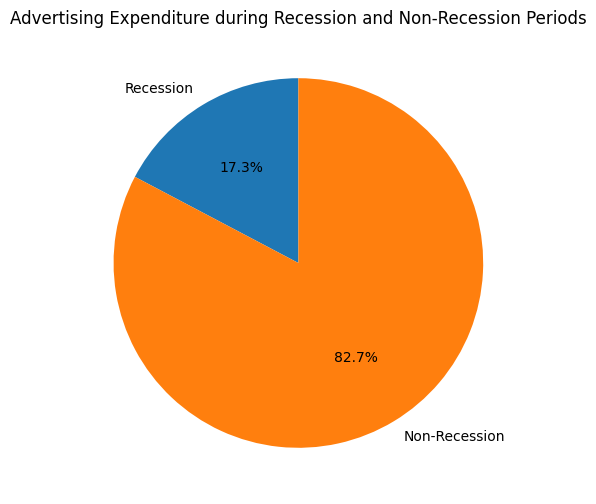

In [43]:
Rdata = df[df['Recession'] == 1]
NRdata = df[df['Recession'] == 0]

# Calculate the total advertising expenditure for both periods
RAtotal = Rdata['Advertising_Expenditure'].sum()
NRAtotal = NRdata['Advertising_Expenditure'].sum()

# Create a pie chart for the advertising expenditure
plt.figure(figsize=(8, 6))

labels = ['Recession', 'Non-Recession']
sizes = [RAtotal, NRAtotal]
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

plt.title('Advertising Expenditure during Recession and Non-Recession Periods')

plt.show()

Expenditure Imbalance: The vast majority of historical advertising capital (82.7%) is deployed during healthy economic conditions.   Recessionary Budget Contraction: During economic downturns, total ad spend contracts to just 17.3% of the overall pie.   Pro-Cyclical Cost Cutting: This stark disparity indicates that instead of increasing marketing efforts to stimulate lagging consumer demand during a downturn, automakers aggressively slash their advertising budgets, treating marketing as a discretionary expense rather than a defensive necessity.   Temporal Caveat: When modeling this data, it is critical to recognize that this pie chart represents total historical volume rather than a normalized annualized average. The massive 82.7% share is inherently inflated by the fact that macroeconomic expansion periods span significantly more years in the dataset than short-lived recessionary shocks.   

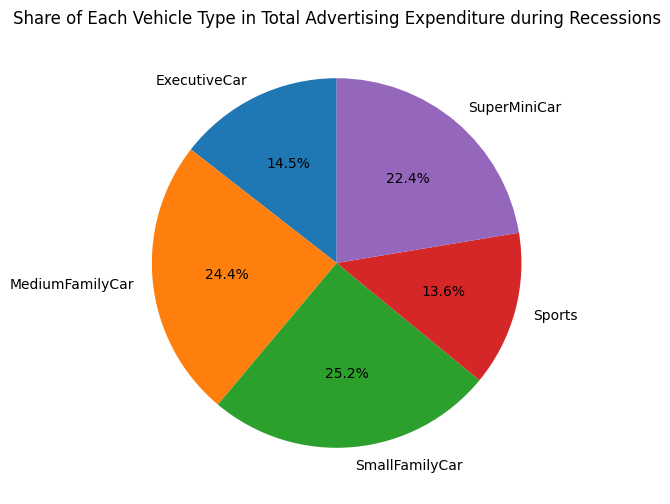

In [44]:
Rdata = df[df['Recession'] == 1]

# Calculate the advertising expenditure by vehicle type during recessions
VTexpenditure = Rdata.groupby('Vehicle_Type')['Advertising_Expenditure'].sum()

# Create a pie chart for the share of each vehicle type in total expenditure during recessions
plt.figure(figsize=(8, 6))

labels = VTexpenditure.index
sizes = VTexpenditure.values
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=90)

plt.title('Share of Each Vehicle Type in Total Advertising Expenditure during Recessions')

plt.show()

Expenditure Imbalance: The vast majority of historical advertising capital (82.7%) is deployed during healthy economic conditions.   Recessionary Budget Contraction: During economic downturns, total ad spend contracts to just 17.3% of the overall pie.   Pro-Cyclical Cost Cutting: This stark disparity indicates that instead of increasing marketing efforts to stimulate lagging consumer demand during a downturn, automakers aggressively slash their advertising budgets, treating marketing as a discretionary expense rather than a defensive necessity.   Temporal Caveat: When modeling this data, it is critical to recognize that this pie chart represents total historical volume rather than a normalized annualized average. The massive 82.7% share is inherently inflated by the fact that macroeconomic expansion periods span significantly more years in the dataset than short-lived recessionary shocks.  

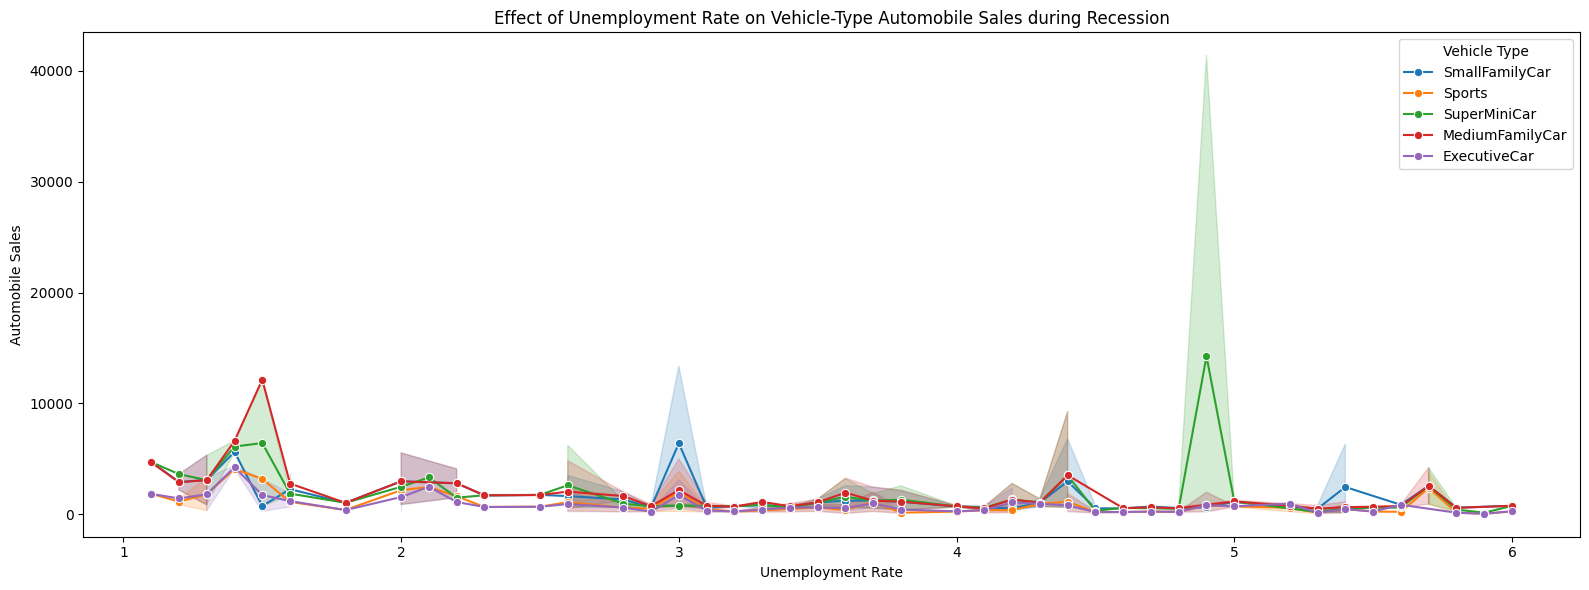

In [45]:
# Assuming 'df' is your dataset
df_rec = df[df['Recession'] == 1]

# Set figure size
plt.figure(figsize=(16, 6))

# Create line plot showing effect of unemployment rate on automobile sales, by vehicle type
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

# Customize labels, legend, and title
plt.title('Effect of Unemployment Rate on Vehicle-Type Automobile Sales during Recession')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.legend(title='Vehicle Type')

# Show plot
plt.tight_layout()
plt.show()

Baseline Stagnation: Across the vast majority of the unemployment spectrum (from 1.0 to 6.0), sales for all vehicle categories remain uniformly depressed, typically hovering tightly below the 5,000-unit threshold.   Extreme Outliers and Variance: The data is characterized by massive, erratic spikes with exceptionally wide confidence intervals, represented by the large shaded regions. The most extreme anomaly occurs within the SuperMiniCar category near an unemployment rate of 4.9, where sales spike to nearly 15,000 units, accompanied by a variance band extending past 40,000 units.   Category-Specific Demand Shocks: Other isolated surges appear at different unemployment thresholds, such as the MediumFamilyCar peaking near a 1.5 unemployment rate and the SmallFamilyCar spiking near 3.0.   Modeling Implications: The massive confidence bands around these spikes suggest high data sparsity or the presence of uncaptured exogenous variables—such as temporary government stimulus programs, targeted dealer incentives, or large corporate fleet liquidations—occurring at those specific unemployment marks.

In [48]:
import requests

def download(url, filename):
    response = requests.get(url)
    response.raise_for_status()
    with open(filename, "wb") as f:
        f.write(response.content)

path = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DV0101EN-SkillsNetwork/Data%20Files/us-states.json'
download(path, "us-states.json")

filename = "us-states.json"

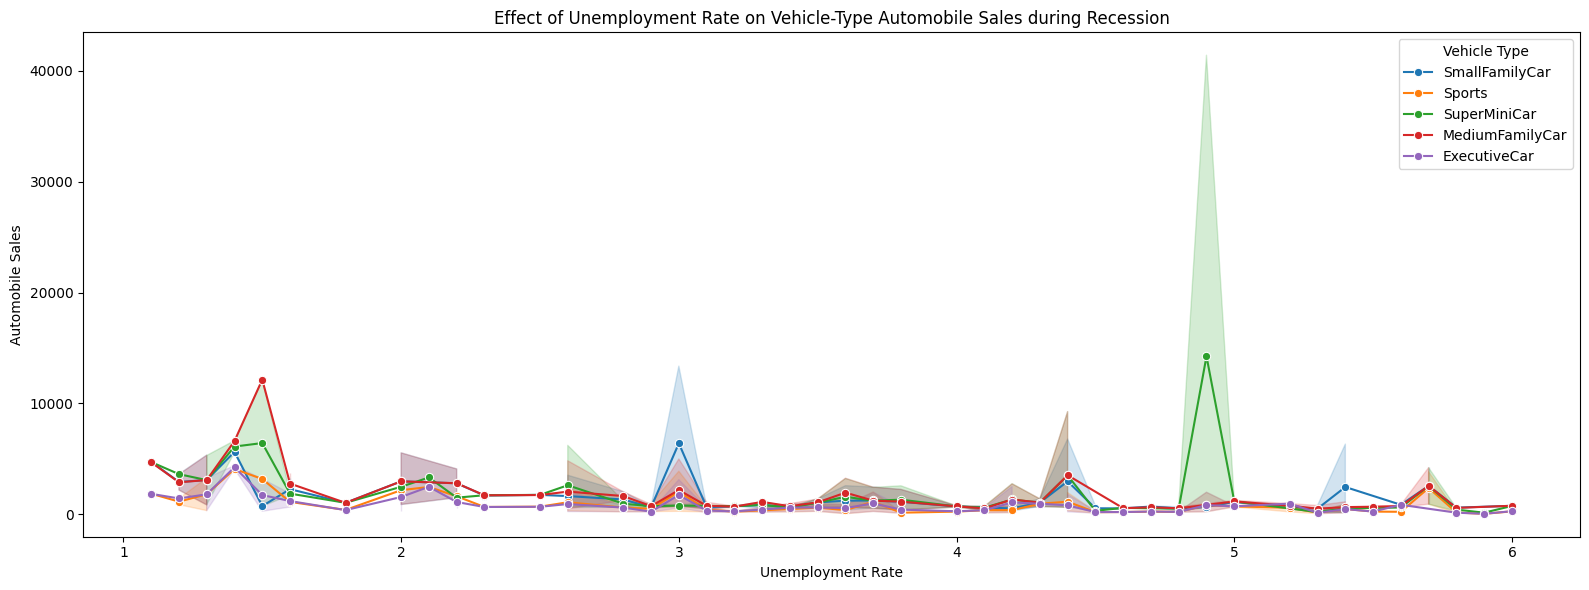

In [50]:
# Assuming 'df' is your dataset
df_rec = df[df['Recession'] == 1]

# Set figure size
plt.figure(figsize=(16, 6))

# Create line plot showing effect of unemployment rate on automobile sales, by vehicle type
sns.lineplot(
    data=df_rec,
    x='unemployment_rate',
    y='Automobile_Sales',
    hue='Vehicle_Type',
    marker='o'
)

# Customize labels, legend, and title
plt.title('Effect of Unemployment Rate on Vehicle-Type Automobile Sales during Recession')
plt.xlabel('Unemployment Rate')
plt.ylabel('Automobile Sales')
plt.legend(title='Vehicle Type')

# Show plot
plt.tight_layout()
plt.show()

In [51]:
html.H1(
    'Automobile Sales Statistics Dashboard',
    style={'textAlign': 'center', 'color': '#503D36', 'font-size': 24}
)

H1(children='Automobile Sales Statistics Dashboard', style={'textAlign': 'center', 'color': '#503D36', 'font-size': 24})

In [52]:
dcc.Dropdown(
    id='dropdown-statistics',
    options=[
        {'label': 'Yearly Statistics', 'value': 'Yearly Statistics'},
        {'label': 'Recession Period Statistics', 'value': 'Recession Period Statistics'}
    ],
    placeholder='Select a report type',
    value='Select Statistics',
    style={'width': '80%', 'padding': '3px', 'font-size': '20px', 'text-align-last': 'center'}
)

Dropdown(options=[{'label': 'Yearly Statistics', 'value': 'Yearly Statistics'}, {'label': 'Recession Period Statistics', 'value': 'Recession Period Statistics'}], value='Select Statistics', placeholder='Select a report type', style={'width': '80%', 'padding': '3px', 'font-size': '20px', 'text-align-last': 'center'}, id='dropdown-statistics')

In [53]:
html.Div([
    html.Div(id='output-container', className='chart-grid', style={'display': 'flex'}),
])

Div([Div(id='output-container', className='chart-grid', style={'display': 'flex'})])

In [54]:
@app.callback(
    Output(component_id='select-year', component_property='disabled'),
    Input(component_id='dropdown-statistics', component_property='value'))
def update_input_container(selected_statistics):
    if selected_statistics == 'Yearly Statistics':
        return False
    else:
        return True

In [55]:
# Plot 1: Automobile sales fluctuate over Recession Period (year wise) using line chart
yearly_rec = recession_data.groupby('Year')['Automobile_Sales'].mean().reset_index()
R_chart1 = dcc.Graph(
    figure=px.line(yearly_rec,
        x='Year',
        y='Automobile_Sales',
        title="Average Automobile Sales fluctuation over Recession Period"))

# Plot 2: Average number of vehicles sold by vehicle type (bar chart)
average_sales = recession_data.groupby('Vehicle_Type')['Automobile_Sales'].mean().reset_index()
R_chart2 = dcc.Graph(
    figure=px.bar(average_sales,
        x='Vehicle_Type',
        y='Automobile_Sales',
        title="Average Number of Vehicles Sold by Vehicle Type"))

# Plot 3: Total expenditure share by vehicle type during recessions (pie chart)
exp_rec = recession_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum().reset_index()
R_chart3 = dcc.Graph(
    figure=px.pie(exp_rec,
        values='Advertising_Expenditure',
        names='Vehicle_Type',
        title="Total Advertising Expenditure Share by Vehicle Type during Recessions"))

# Plot 4: Effect of unemployment rate on vehicle type and sales (bar chart)
unemp_data = recession_data.groupby(['unemployment_rate', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()
R_chart4 = dcc.Graph(figure=px.bar(unemp_data,
    x='unemployment_rate',
    y='Automobile_Sales',
    color='Vehicle_Type',
    labels={'unemployment_rate': 'Unemployment Rate', 'Automobile_Sales': 'Average Automobile Sales'},
    title='Effect of Unemployment Rate on Vehicle Type and Sales'))

return [
    html.Div(className='chart-item', children=[html.Div(children=R_chart1), html.Div(children=R_chart2)], style={'display': 'flex'}),
    html.Div(className='chart-item', children=[html.Div(children=R_chart3), html.Div(children=R_chart4)], style={'display': 'flex'})
]

NameError: name 'recession_data' is not defined

# Automobile Sales Statistics Dashboard (complete, runnable)

Combines all TASK fragments into one working Dash app. Select a report type (Yearly / Recession Period Statistics); Year enables only for Yearly. Run the cell, open the printed URL, and interrupt the kernel to stop.

In [4]:
import pandas as pd
import plotly.express as px
import dash
from dash import dcc, html
from dash.dependencies import Input, Output

# Load the automobile sales data
data = pd.read_csv(
    "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/"
    "d51iMGfp_t0QpO30Lym-dw/automobile-sales.csv"
)

app = dash.Dash(__name__)

year_list = [i for i in range(1980, 2024)]

app.layout = html.Div([
    # TASK 2.1: title
    html.H1(
        'Automobile Sales Statistics Dashboard',
        style={'textAlign': 'center', 'color': '#503D36', 'font-size': 24}
    ),
    # TASK 2.2: dropdowns
    html.Div([
        html.Label("Select Statistics:"),
        dcc.Dropdown(
            id='dropdown-statistics',
            options=[
                {'label': 'Yearly Statistics', 'value': 'Yearly Statistics'},
                {'label': 'Recession Period Statistics', 'value': 'Recession Period Statistics'}
            ],
            value='Select Statistics',
            placeholder='Select a report type',
            style={'width': '80%', 'padding': '3px', 'font-size': '20px', 'text-align-last': 'center'}
        ),
    ]),
    html.Div(dcc.Dropdown(
        id='select-year',
        options=[{'label': i, 'value': i} for i in year_list],
        value='Select Year',
        placeholder='Select a year',
        style={'width': '80%', 'padding': '3px', 'font-size': '20px', 'text-align-last': 'center'}
    )),
    # TASK 2.3: output container
    html.Div([
        html.Div(id='output-container', className='chart-grid', style={'display': 'flex'}),
    ]),
])


# Enable/disable the year dropdown based on report type
@app.callback(
    Output(component_id='select-year', component_property='disabled'),
    Input(component_id='dropdown-statistics', component_property='value'))
def update_input_container(selected_statistics):
    return selected_statistics != 'Yearly Statistics'


# TASK 2.4 + 2.5: main callback rendering the charts
@app.callback(
    Output(component_id='output-container', component_property='children'),
    [Input(component_id='dropdown-statistics', component_property='value'),
     Input(component_id='select-year', component_property='value')])
def update_output_container(selected_statistics, input_year):
    if selected_statistics == 'Recession Period Statistics':
        recession_data = data[data['Recession'] == 1]

        # Plot 1: yearly average sales during recessions
        yearly_rec = recession_data.groupby('Year')['Automobile_Sales'].mean().reset_index()
        R_chart1 = dcc.Graph(figure=px.line(
            yearly_rec, x='Year', y='Automobile_Sales',
            title="Average Automobile Sales fluctuation over Recession Period"))

        # Plot 2: average sales by vehicle type
        average_sales = recession_data.groupby('Vehicle_Type')['Automobile_Sales'].mean().reset_index()
        R_chart2 = dcc.Graph(figure=px.bar(
            average_sales, x='Vehicle_Type', y='Automobile_Sales',
            title="Average Number of Vehicles Sold by Vehicle Type"))

        # Plot 3: ad expenditure share by vehicle type
        exp_rec = recession_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum().reset_index()
        R_chart3 = dcc.Graph(figure=px.pie(
            exp_rec, values='Advertising_Expenditure', names='Vehicle_Type',
            title="Total Advertising Expenditure Share by Vehicle Type during Recessions"))

        # Plot 4: unemployment rate effect
        unemp_data = recession_data.groupby(['unemployment_rate', 'Vehicle_Type'])['Automobile_Sales'].mean().reset_index()
        R_chart4 = dcc.Graph(figure=px.bar(
            unemp_data, x='unemployment_rate', y='Automobile_Sales', color='Vehicle_Type',
            labels={'unemployment_rate': 'Unemployment Rate', 'Automobile_Sales': 'Average Automobile Sales'},
            title='Effect of Unemployment Rate on Vehicle Type and Sales'))

        return [
            html.Div(className='chart-item', children=[html.Div(children=R_chart1), html.Div(children=R_chart2)], style={'display': 'flex'}),
            html.Div(className='chart-item', children=[html.Div(children=R_chart3), html.Div(children=R_chart4)], style={'display': 'flex'})
        ]

    elif input_year and input_year != 'Select Year' and selected_statistics == 'Yearly Statistics':
        yearly_data = data[data['Year'] == input_year]

        # Plot 1: yearly average sales for the whole period
        yas = data.groupby('Year')['Automobile_Sales'].mean().reset_index()
        Y_chart1 = dcc.Graph(figure=px.line(
            yas, x='Year', y='Automobile_Sales',
            title='Yearly Average Automobile Sales'))

        # Plot 2: monthly sales for the selected year
        mas = yearly_data.groupby('Month')['Automobile_Sales'].mean().reset_index()
        Y_chart2 = dcc.Graph(figure=px.line(
            mas, x='Month', y='Automobile_Sales',
            title=f'Total Monthly Automobile Sales in {input_year}'))

        # Plot 3: average vehicles sold by type for the selected year
        avr_vdata = yearly_data.groupby('Vehicle_Type')['Automobile_Sales'].mean().reset_index()
        Y_chart3 = dcc.Graph(figure=px.bar(
            avr_vdata, x='Vehicle_Type', y='Automobile_Sales',
            title=f'Average Vehicles Sold by Vehicle Type in the year {input_year}'))

        # Plot 4: ad expenditure share by vehicle type for the selected year
        exp_data = yearly_data.groupby('Vehicle_Type')['Advertising_Expenditure'].sum().reset_index()
        Y_chart4 = dcc.Graph(figure=px.pie(
            exp_data, values='Advertising_Expenditure', names='Vehicle_Type',
            title=f'Total Advertisement Expenditure for Each Vehicle in the year {input_year}'))

        return [
            html.Div(className='chart-item', children=[html.Div(children=Y_chart1), html.Div(children=Y_chart2)], style={'display': 'flex'}),
            html.Div(className='chart-item', children=[html.Div(children=Y_chart3), html.Div(children=Y_chart4)], style={'display': 'flex'})
        ]

    return None


if __name__ == '__main__':
    app.run(debug=False)
